<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Audio Feature Extraction](https://github.com/Query-farm/vgi-audio)

Measure duration, tempo, loudness, spectral timbre, MFCCs and musical key of audio files with librosa.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-audio/blob/main/notebooks/02_a_tempo_estimate_is_not_a_beat_list.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-audio/blob/main/notebooks/README.md)


## A tempo estimate is not a detected beat list

**Can a clip have a numeric tempo estimate but no detected beats?** We will inspect the worker’s two built-in synthetic clips, retain an invalid-byte control, and compare its whole-clip `tempo()` scalar with intervals from `beats()`. A local reporting-window experiment changes which already-detected events we summarize; it never crops or reanalyzes the audio.

These tiny test signals are neither recordings nor a tempo benchmark. The click clip is described as 120 BPM; that description is a nominal source property, not a claim that every detector must return exactly 120. The short steady tone can expose algorithmic behavior without having a reliable musical beat. [Setup and limitations](README.md).


### Choose the reporting window

`WINDOW_END_S` is the excluded upper endpoint in seconds, greater than zero and at most 2. Default **2.0**; experiment **1.25**. Retain event times in **[0, WINDOW_END_S)**. This is selection over a materialized beat table, not a shorter input recording. The full-clip tempo estimate and source bytes should remain fixed.


In [1]:
WINDOW_END_S = 2.0  # seconds; excluded endpoint; experiment 1.25


In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.25":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.25"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")


In [3]:
from IPython.display import display
from vgi_notebooks import check_runtime, connect, theme, prose, prepare

check_runtime()
prepare("audio")
import audio_example as example

example.validate_window(WINDOW_END_S)
session = connect(globals())
theme()


### Connect to the same released extractor

The literal command starts the public **v0.4.0** tag with release-owned dependencies in an isolated Python 3.13 worker environment. It needs initial package and extension downloads but no local source checkout, credentials or audio service. Cold librosa/Numba startup can take tens of seconds. Both notebooks use the same verified runtime path.


In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'audio' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-audio@v0.4.0 vgi-audio-worker');
SELECT extension_name,extension_version,loaded FROM duckdb_extensions() WHERE extension_name='vgi';


,extension_name,extension_version,loaded
0,vgi,e75482339d,True


### Materialize the catalog inputs and preserve their bytes

`example_clips` supplies the actual embedded WAV tone and FLAC click bytes, decoded metadata and a **detected** beat count. That count is computed using the same beat detector; agreement with a later call is a consistency check, not independent ground truth. We read the table once and retain its SHA256 values.

The scalar API accepts a column of bytes. The table APIs accept literal arguments rather than a lateral column or subquery. The short folded input step therefore copies the two catalog byte strings unchanged to generated local files, checks their hashes, and uses visible literal paths below. The `.bin` suffix leaves decoding to the file header. No replacement audio is supplied. A third SQL input is explicitly invalid text bytes.


In [5]:
%%sql
CREATE TABLE sample_bytes AS SELECT * FROM audio.main.example_clips;
CREATE TABLE inputs AS
SELECT name,description,duration AS catalog_duration_s,sample_rate AS catalog_rate_hz,
 channels AS catalog_channels,beat_count AS catalog_detected_count,audio FROM sample_bytes
UNION ALL SELECT 'invalid','Authored invalid bytes',NULL,NULL,NULL,NULL,'not audio'::BLOB;
CREATE TABLE tempo_rows AS SELECT name,audio.main.tempo(audio) AS tempo_bpm FROM inputs;
SELECT name,description,catalog_duration_s,catalog_rate_hz,catalog_channels,catalog_detected_count,
 octet_length(audio) AS file_bytes,sha256(audio) AS source_sha256 FROM inputs ORDER BY name;


,name,description,catalog_duration_s,catalog_rate_hz,catalog_channels,catalog_detected_count,file_bytes,source_sha256
0,click,"A 120 BPM mono click track (sharp, evenly-spac...",2.0,6000,1,3,2237,7845919400e2e0089fa61cf5961a4f88874a96243bd0a9...
1,invalid,Authored invalid bytes,NaN,<NA>,<NA>,<NA>,9,e23b51a40d21aad70200ec1f08c6e4883d6ca40c22b6ff...
2,tone,"A short 60 Hz mono sine tone (a steady, tonal ...",0.5,200,1,0,244,cf4b34ff9c024e425fbcdee7283e6b75ce4ab6ef8ebe12...


In [6]:
%%sql builtin_bytes <<
SELECT name,audio,sha256(audio) AS sha256 FROM sample_bytes ORDER BY name;


In [7]:
example.write_builtin_inputs(builtin_bytes)


### Decode metadata and the full event lists once

`audio_info` reports native duration, sample rate and channel count; feature analysis internally resamples to 22,050 Hz mono. `beats` returns a zero-based output sequence and time in seconds from clip start. The complete event lists are materialized before window selection. Invalid non-NULL bytes return no rows; SQL NULL table arguments are rejected at bind time and are not used here.

A left join will retain all three inputs. Zero detected events from a decodable tone differs from no available measurement on invalid bytes. A positive tempo estimate does not certify either a reliable pulse or a nonempty beat list.


In [8]:
%%sql
CREATE TABLE info_rows AS
SELECT 'click' AS name,* FROM audio.main.audio_info('artifacts/sample_audio/click.bin')
UNION ALL SELECT 'tone',* FROM audio.main.audio_info('artifacts/sample_audio/tone.bin')
UNION ALL SELECT 'invalid',* FROM audio.main.audio_info('not audio'::BLOB);
CREATE TABLE beat_rows AS
SELECT 'click' AS name,* FROM audio.main.beats('artifacts/sample_audio/click.bin')
UNION ALL SELECT 'tone',* FROM audio.main.beats('artifacts/sample_audio/tone.bin')
UNION ALL SELECT 'invalid',* FROM audio.main.beats('not audio'::BLOB);
SELECT name,seq,time FROM beat_rows ORDER BY name,seq;


,name,seq,time
0,click,0,0.534059
1,click,1,1.044898
2,click,2,1.532517


### Keep the denominator before calculating a beat-grid rate

Select events in the half-open reporting window, then compute consecutive time gaps within each selected clip. Define the grid rate as **60 / median(gap seconds)** only when at least one gap exists. A single event has no interval and therefore no grid-rate estimate. This is a different calculation from librosa’s whole-clip tempo estimator, even though both are expressed in BPM.


In [9]:
%%sql
CREATE TABLE selected_beats AS SELECT * FROM beat_rows WHERE time>=0 AND time<{{ WINDOW_END_S }};
CREATE TABLE selected_gaps AS
SELECT name,time-lag(time) OVER(PARTITION BY name ORDER BY seq) AS gap_s FROM selected_beats;
CREATE TABLE population AS
WITH full_counts AS (SELECT name,count(*) AS events FROM beat_rows GROUP BY name),
 selected_counts AS (SELECT name,count(*) AS events FROM selected_beats GROUP BY name),
 gaps AS (SELECT name,count(gap_s) AS gaps,median(gap_s) AS median_gap_s FROM selected_gaps GROUP BY name)
SELECT i.name,m.duration AS duration_s,m.sample_rate AS native_rate_hz,m.channels,
 t.tempo_bpm,
 CASE WHEN m.duration IS NOT NULL THEN coalesce(f.events,0) END AS full_beats,
 CASE WHEN m.duration IS NOT NULL THEN coalesce(s.events,0) END AS selected_beats,
 CASE WHEN m.duration IS NOT NULL THEN coalesce(g.gaps,0) END AS gaps,
 g.median_gap_s,60.0/g.median_gap_s AS grid_bpm
FROM inputs i LEFT JOIN info_rows m USING(name) LEFT JOIN tempo_rows t USING(name)
LEFT JOIN full_counts f USING(name) LEFT JOIN selected_counts s USING(name) LEFT JOIN gaps g USING(name);
SELECT * FROM population ORDER BY CASE name WHEN 'click' THEN 0 WHEN 'tone' THEN 1 ELSE 2 END;


,name,duration_s,native_rate_hz,channels,tempo_bpm,full_beats,selected_beats,gaps,median_gap_s,grid_bpm
0,click,2.0,6000,1,117.453835,3,3,2,0.499229,120.18532
1,tone,0.5,200,1,135.999178,0,0,0,NaN,NaN
2,invalid,NaN,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,NaN,NaN


In [10]:
%%sql population_frame <<
SELECT * FROM population ORDER BY CASE name WHEN 'click' THEN 0 WHEN 'tone' THEN 1 ELSE 2 END;


In [11]:
click = population_frame.loc[population_frame.name == "click"].iloc[0]
tone = population_frame.loc[population_frame.name == "tone"].iloc[0]
prose(f"All **{len(population_frame)} inputs** remain in the table. The click clip has **{int(click.full_beats)} full-list beats**, of which **{int(click.selected_beats)}** are inside the window, giving **{int(click.gaps)} intervals**. Its full-clip tempo remains **{click.tempo_bpm:.2f} BPM**. The tone has **{int(tone.full_beats)} detected beats** despite a numeric tempo estimate of **{tone.tempo_bpm:.2f} BPM**. Invalid bytes retain unavailable metadata and estimates rather than becoming a silent zero-beat clip.")


All **3 inputs** remain in the table. The click clip has **3 full-list beats**, of which **3** are inside the window, giving **2 intervals**. Its full-clip tempo remains **117.45 BPM**. The tone has **0 detected beats** despite a numeric tempo estimate of **136.00 BPM**. Invalid bytes retain unavailable metadata and estimates rather than becoming a silent zero-beat clip.

In [12]:
%%sql event_frame <<
SELECT *,time>=0 AND time<{{ WINDOW_END_S }} AS selected FROM beat_rows ORDER BY name,seq;


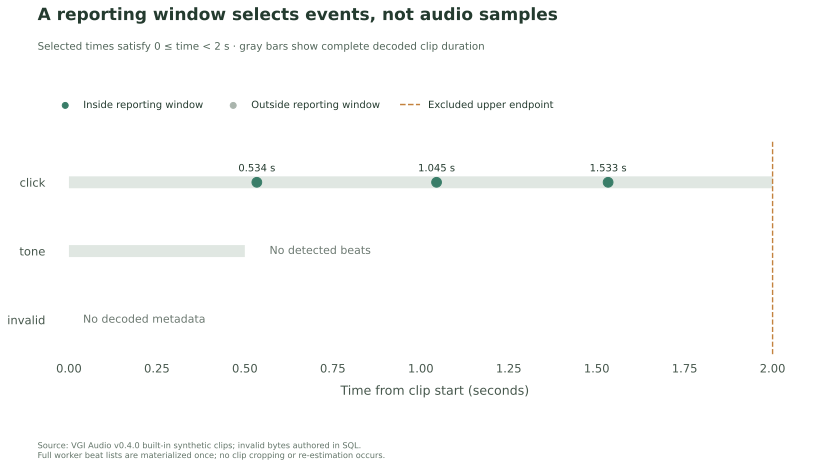

In [13]:
example.event_timeline(population_frame, event_frame, WINDOW_END_S)


### Interpret the two rate calculations separately

A median of one or two detected intervals is highly sensitive to which events remain. The full-clip estimator can still return a number for the steady tone, while no event-based rate can be calculated for it. Neither returned number is a confidence score. The figure keeps absent estimates explicit instead of placing them at zero BPM.


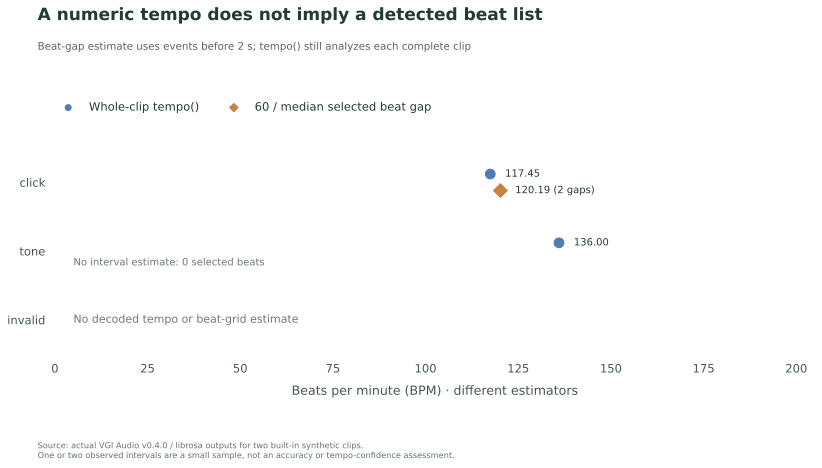

The selected click-event grid rate is **120.19 BPM**, based on **2 intervals**; the full-clip estimate is **117.45 BPM**. The reporting endpoint changes the available event intervals, not the input samples or the already-computed tempo. Agreement between these numbers would not establish estimator accuracy.

In [14]:
example.tempo_comparison(population_frame, WINDOW_END_S)
rate = "unavailable" if int(click.gaps) == 0 else f"{click.grid_bpm:.2f} BPM"
prose(f"The selected click-event grid rate is **{rate}**, based on **{int(click.gaps)} intervals**; the full-clip estimate is **{click.tempo_bpm:.2f} BPM**. The reporting endpoint changes the available event intervals, not the input samples or the already-computed tempo. Agreement between these numbers would not establish estimator accuracy.")


### Check identity, selection and availability

The checks reconcile file hashes with the actual catalog bytes, native metadata with the independent table call, and catalog beat counts with the full event list. They verify selected membership and interval arithmetic while keeping valid zero-event and invalid-input rows distinct. Because the catalog count uses the same detector, its agreement is not an independent accuracy test.


In [15]:
%%sql checks <<
SELECT 'all three inputs retained' AS check_name,(SELECT count(*) FROM population)=3 AS passed
UNION ALL SELECT 'two catalog byte copies match SQL hashes',count(*)=2 AND bool_and(sha256(r.content)=sha256(s.audio))
 FROM read_blob('artifacts/sample_audio/*.bin') r JOIN sample_bytes s ON regexp_extract(r.filename,'([^/]+)\.bin$',1)=s.name
UNION ALL SELECT 'native metadata matches catalog',count(*)=2 AND bool_and(m.duration=i.catalog_duration_s AND m.sample_rate=i.catalog_rate_hz AND m.channels=i.catalog_channels)
 FROM info_rows m JOIN inputs i USING(name)
UNION ALL SELECT 'full beat count matches catalog detector count',bool_and(p.full_beats=i.catalog_detected_count) FROM population p JOIN inputs i USING(name) WHERE i.catalog_detected_count IS NOT NULL
UNION ALL SELECT 'event sequences unique and inside full clip',count(*)=count(DISTINCT (b.name,b.seq)) AND bool_and(b.time>=0 AND b.time<m.duration) FROM beat_rows b JOIN info_rows m USING(name)
UNION ALL SELECT 'selected rows obey half-open bound',coalesce(bool_and(time>=0 AND time<{{ WINDOW_END_S }}),true) FROM selected_beats
UNION ALL SELECT 'every eligible event selected',count(*)=0 FROM ((SELECT * FROM beat_rows WHERE time>=0 AND time<{{ WINDOW_END_S }} EXCEPT SELECT * FROM selected_beats) UNION ALL (SELECT * FROM selected_beats EXCEPT SELECT * FROM beat_rows WHERE time>=0 AND time<{{ WINDOW_END_S }}))
UNION ALL SELECT 'gap count follows selected population',bool_and(gaps=greatest(selected_beats-1,0)) FROM population WHERE duration_s IS NOT NULL
UNION ALL SELECT 'finite increasing event intervals',coalesce(bool_and(isfinite(gap_s) AND gap_s>0),true) FROM selected_gaps WHERE gap_s IS NOT NULL
UNION ALL SELECT 'tone has zero detected events and no grid estimate',full_beats=0 AND selected_beats=0 AND grid_bpm IS NULL AND tempo_bpm IS NOT NULL FROM population WHERE name='tone'
UNION ALL SELECT 'invalid remains unavailable',duration_s IS NULL AND tempo_bpm IS NULL AND full_beats IS NULL AND grid_bpm IS NULL FROM population WHERE name='invalid';


In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), "An input or event-accounting check failed"
prose(f"**All {len(checks)} SQL checks pass.** Byte identity, population retention and interval arithmetic reconcile; these checks do not turn detector agreement into a tempo benchmark.")


,check_name,passed
0,all three inputs retained,True
1,two catalog byte copies match SQL hashes,True
2,native metadata matches catalog,True
3,full beat count matches catalog detector count,True
4,event sequences unique and inside full clip,True
5,selected rows obey half-open bound,True
6,every eligible event selected,True
7,gap count follows selected population,True
8,finite increasing event intervals,True
9,tone has zero detected events and no grid esti...,True


**All 11 SQL checks pass.** Byte identity, population retention and interval arithmetic reconcile; these checks do not turn detector agreement into a tempo benchmark.

### Experiment: exclude the final detected click

Change only **WINDOW_END_S from 2.0 to 1.25**. Predict which detected events remain in [0, 1.25), how many consecutive intervals are left, and whether `tempo()` changes. The timeline should retain the excluded event in gray so its removal from the summary remains visible.

Compare the interval-derived rate with its default, then inspect the unchanged source metadata and full-clip scalar. This is a reporting sensitivity demonstration over very few events, not a musical timing judgment. The README command saves the experiment separately; keep 2.0 as the published default.


In [17]:
session.close()


<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-audio](https://github.com/Query-farm/vgi-audio)
